In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dataSet = pd.read_csv("dataSet.csv")



# Задание 1: Первичный визуальный анализ данных

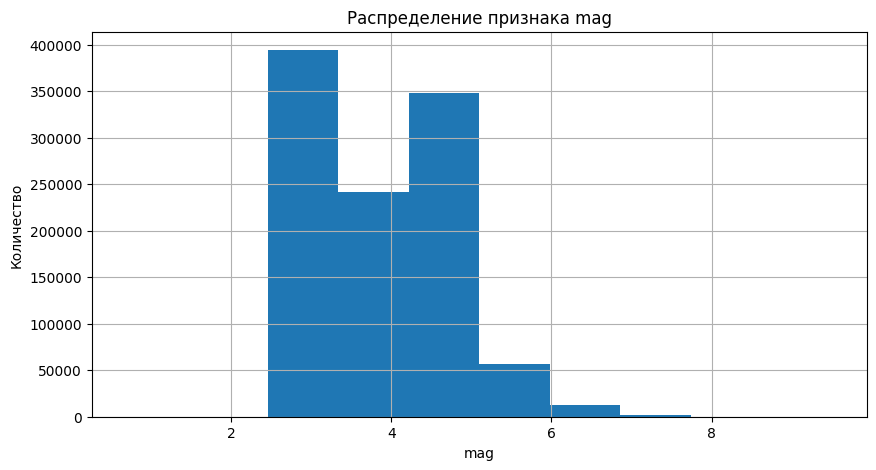

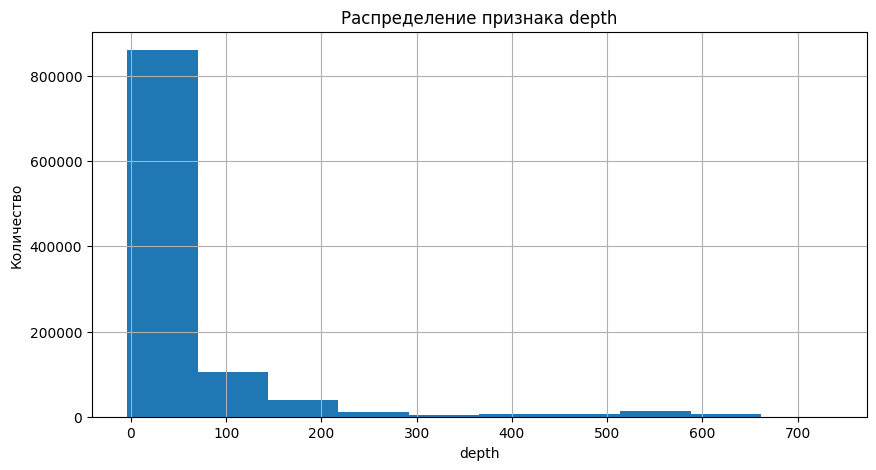

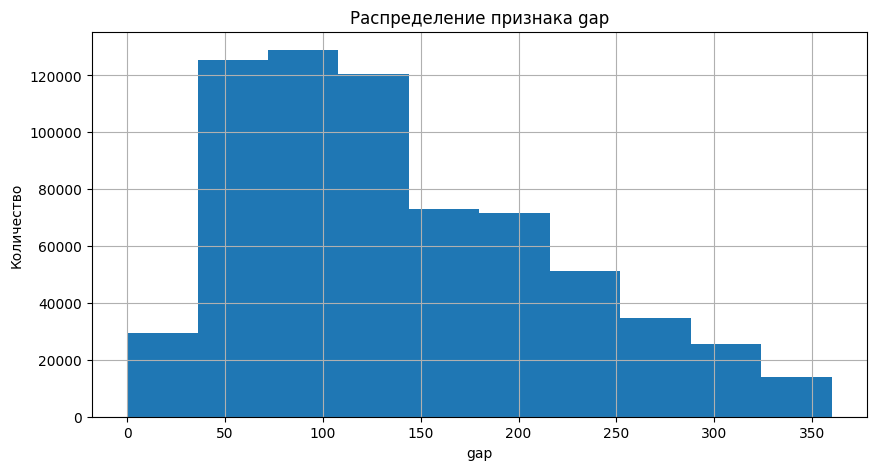

In [27]:
numFeatures = ["mag", "depth", "gap"]
for col in numFeatures:
    plt.figure(figsize=(10,5))
    dataSet[col].dropna().hist()
    plt.title(f"Распределение признака {col}")
    plt.xlabel(col)
    plt.ylabel("Количество")
    plt.show()


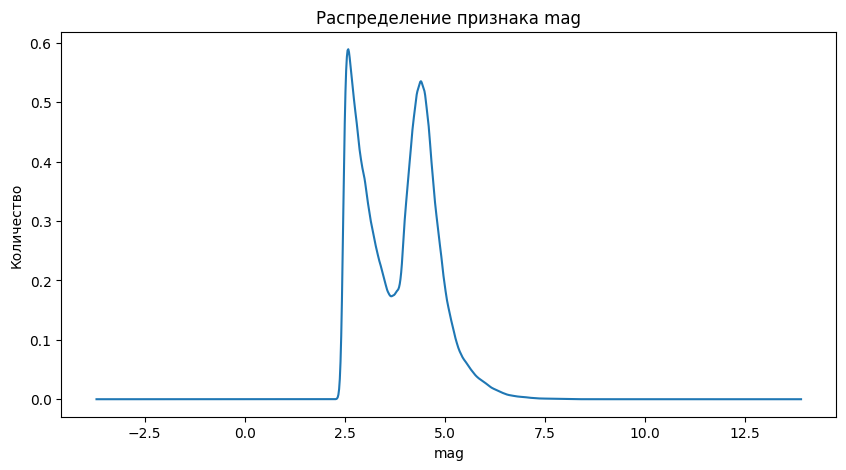

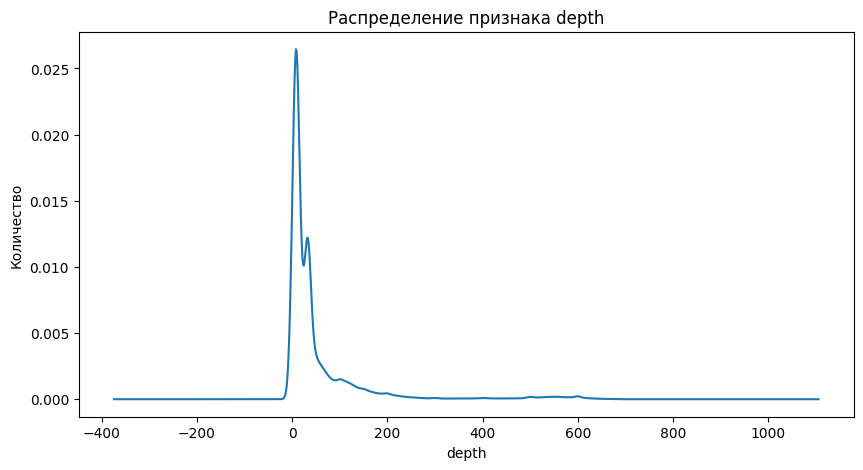

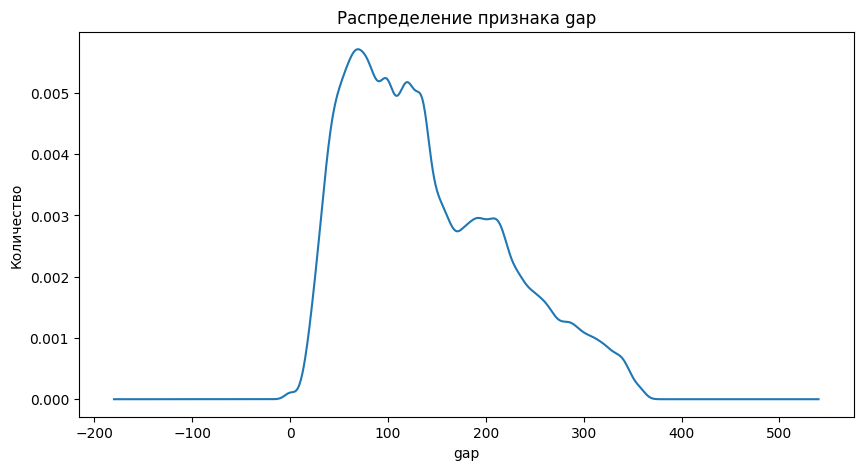

In [54]:
for col in numFeatures:
    plt.figure(figsize=(10,5))
    dataSet[col].dropna().plot.density()
    plt.title(f"Распределение признака {col}")
    plt.xlabel(col)
    plt.ylabel("Количество")
    plt.show()

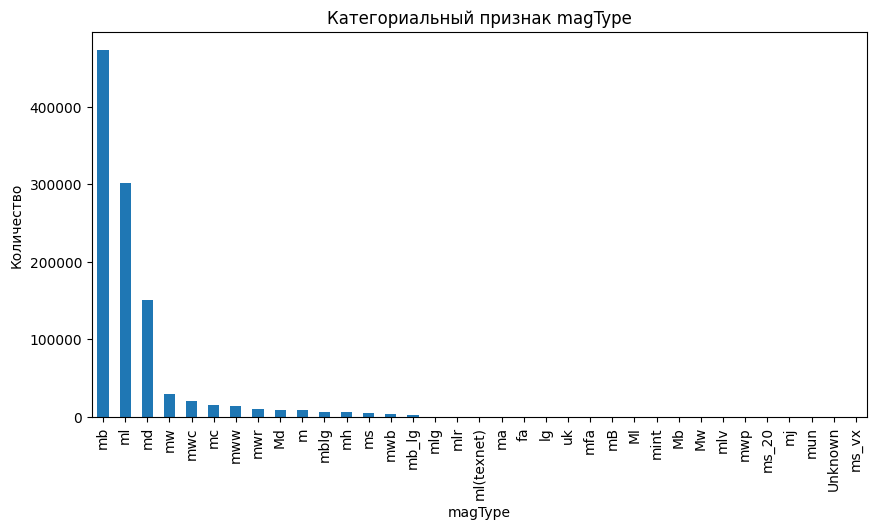

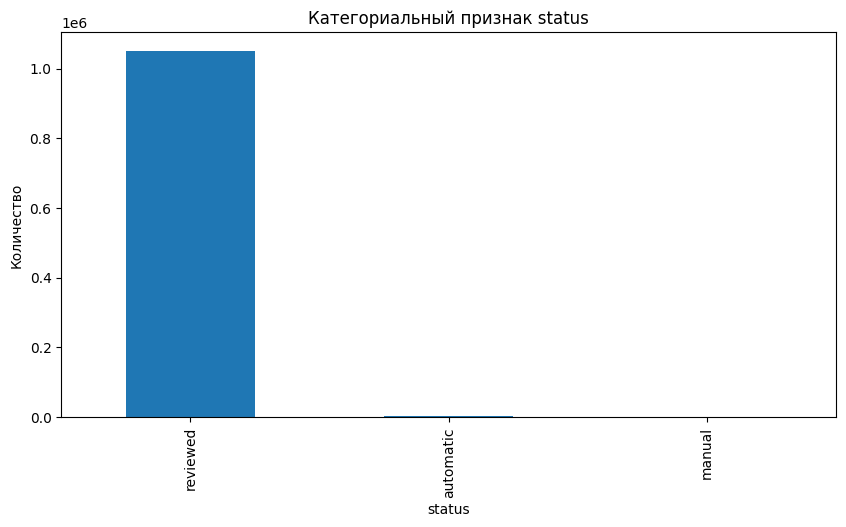

In [29]:
catFeatures = ["magType", "status"]
for col in catFeatures:
    plt.figure(figsize=(10,5))
    dataSet[col].value_counts().plot(kind="bar")
    plt.title(f"Категориальный признак {col}")
    plt.xlabel(col)
    plt.ylabel("Количество")
    plt.show()    

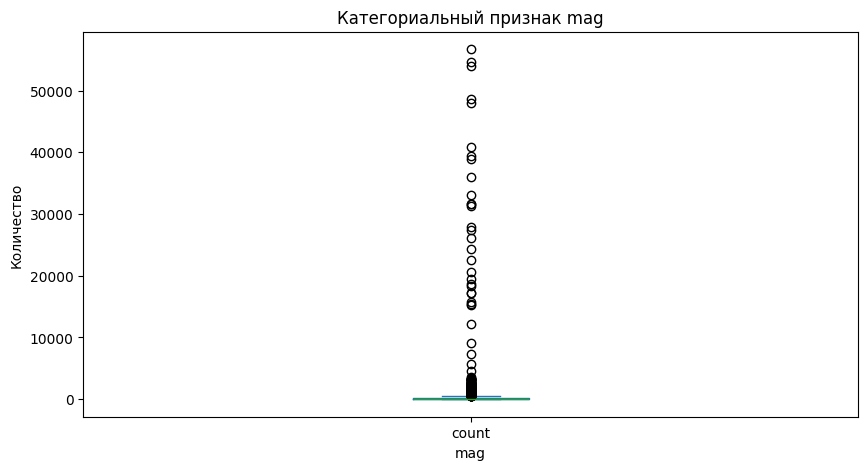

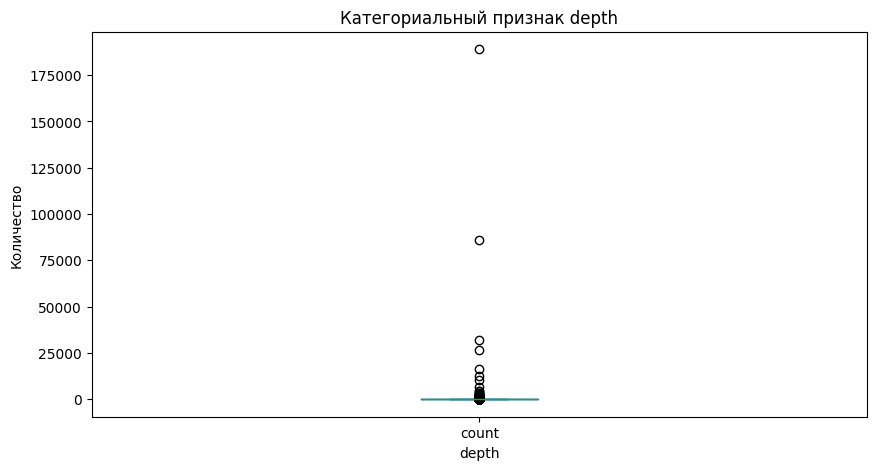

In [30]:
boxFeatures = ["mag", "depth"]
for col in boxFeatures:
    plt.figure(figsize=(10,5))
    dataSet[col].value_counts().plot(kind="box")
    plt.title(f"Категориальный признак {col}")
    plt.xlabel(col)
    plt.ylabel("Количество")
    plt.show()


# Задание 2: Ошибки визуализации

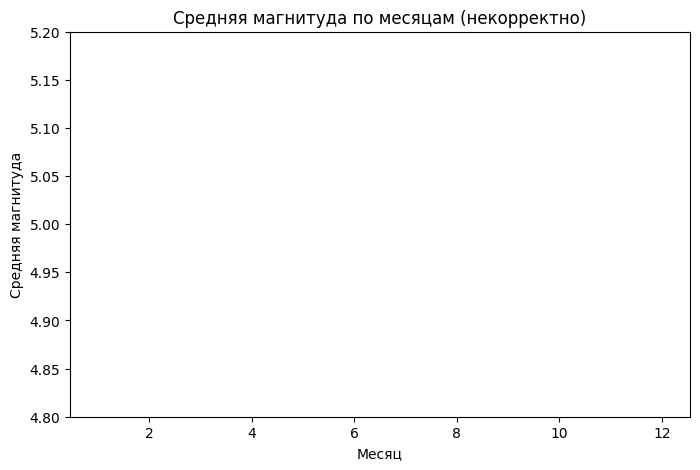

In [31]:
monthly_mag = dataSet.groupby('month')['mag'].mean()
plt.figure(figsize=(8,5))
plt.plot(monthly_mag.index,
         monthly_mag.values)
# ОШИБКА
plt.ylim(4.8, 5.2)
plt.title('Средняя магнитуда по месяцам (некорректно)')
plt.xlabel('Месяц')
plt.ylabel('Средняя магнитуда')
plt.show()

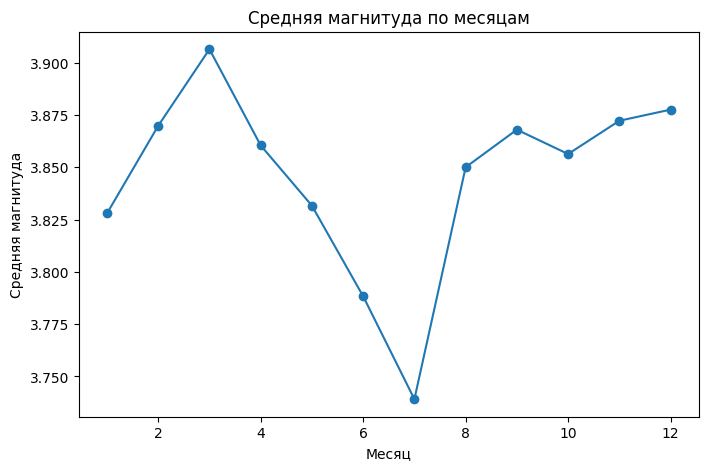

In [32]:
plt.figure(figsize=(8,5))
plt.plot(monthly_mag.index,
         monthly_mag.values,
         marker='o')
plt.title('Средняя магнитуда по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Средняя магнитуда')
plt.show()

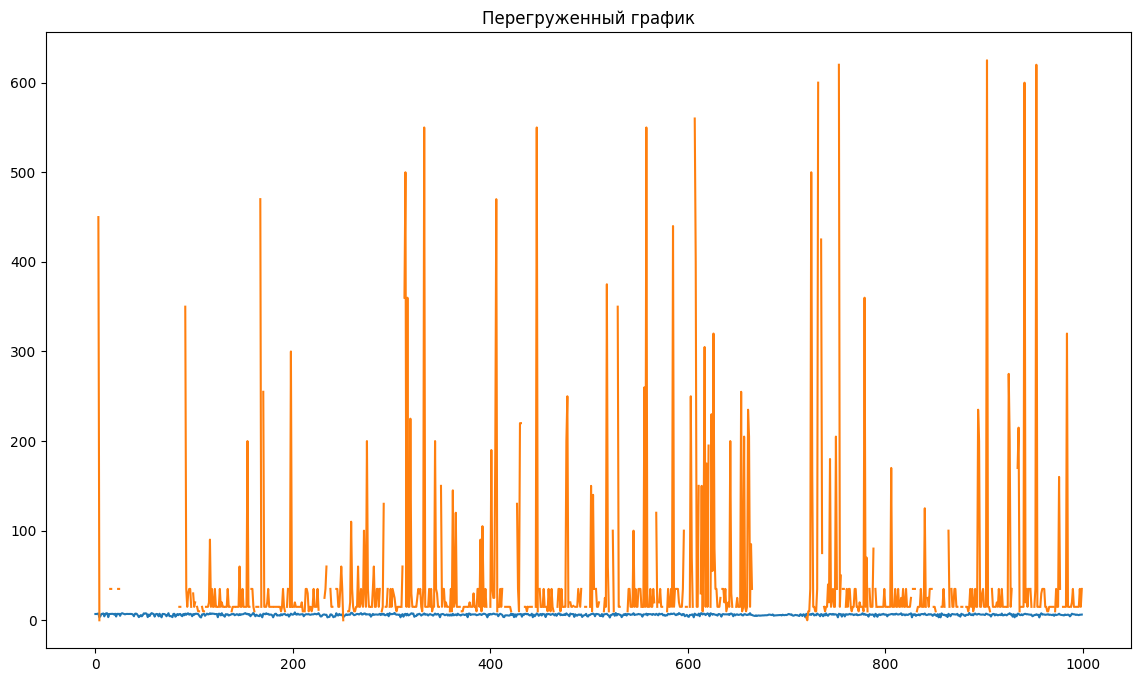

In [33]:
plt.figure(figsize=(14,8))
for col in ['mag', 'depth', 'gap', 'rms', 'dmin']:
    plt.plot(dataSet[col].head(1000), label=col)
plt.title('Перегруженный график')
plt.show()

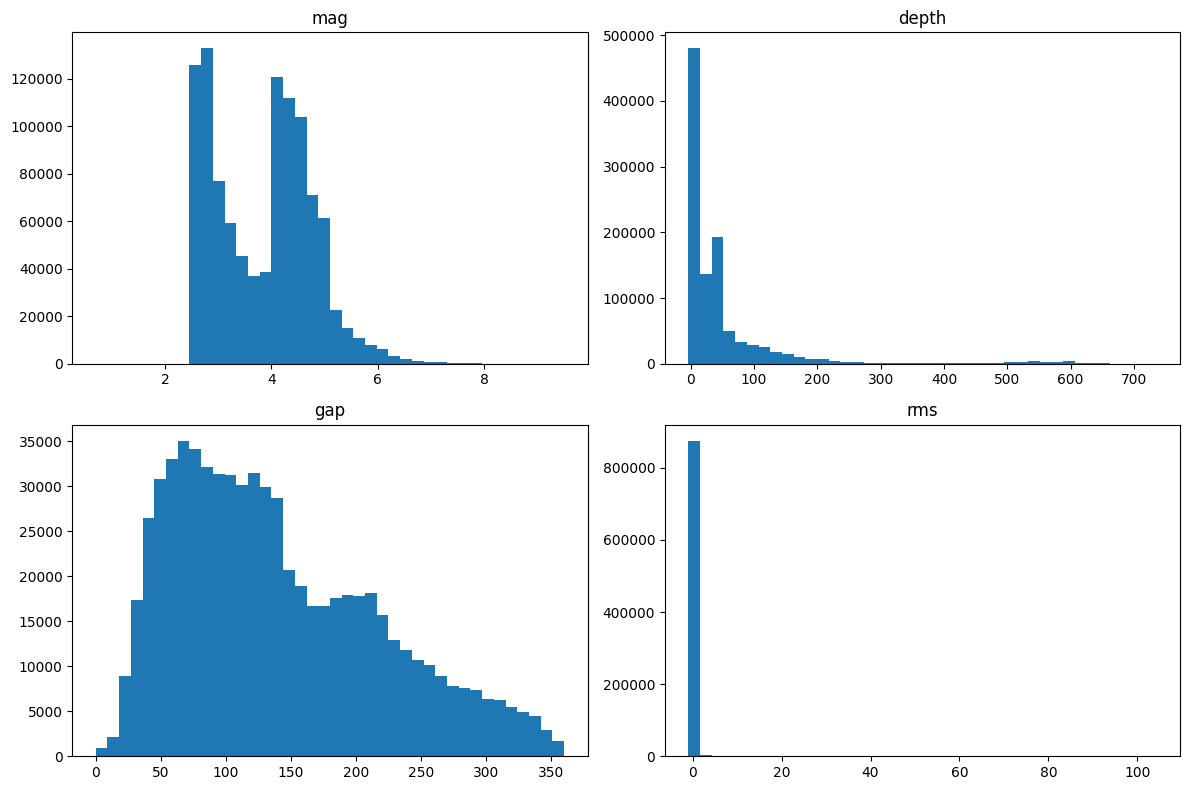

In [34]:
features = ['mag', 'depth', 'gap', 'rms']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, feature in enumerate(features):
    row = i // 2
    col = i % 2
    axes[row, col].hist(dataSet[feature].dropna(),
                        bins=40)
    axes[row, col].set_title(feature)
plt.tight_layout()
plt.show()

# Задание 3: Анализ взаимосвязей между признаками

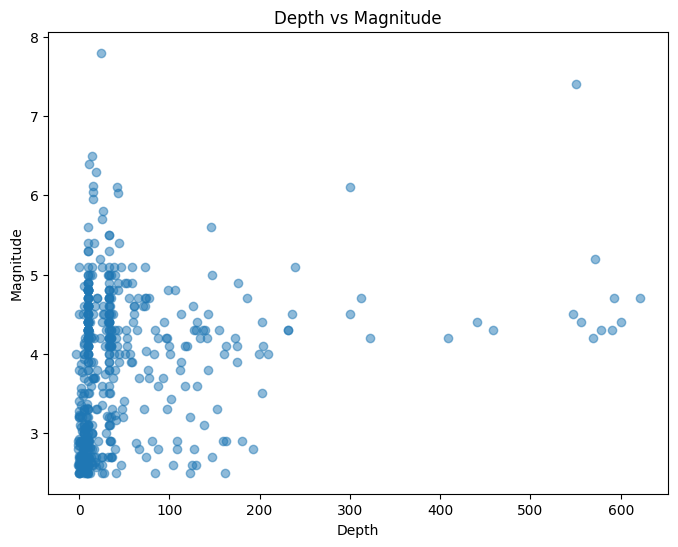

In [35]:
sample_df = dataSet.sample(500)
plt.figure(figsize=(8, 6))
plt.scatter(sample_df['depth'],
            sample_df['mag'],
            alpha=0.5)
plt.title('Depth vs Magnitude')
plt.xlabel('Depth')
plt.ylabel('Magnitude')
plt.show()

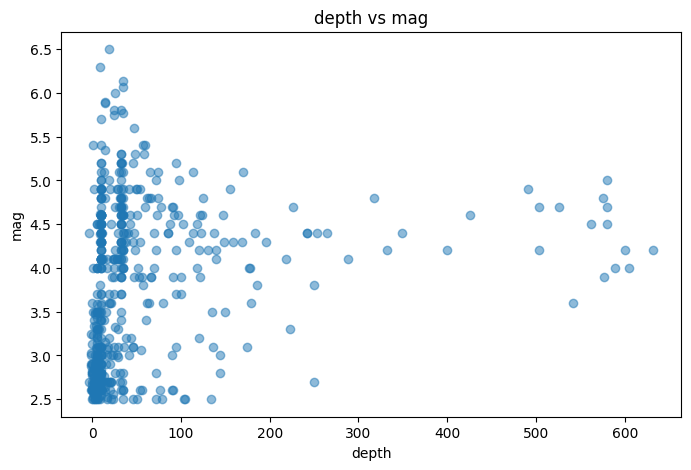

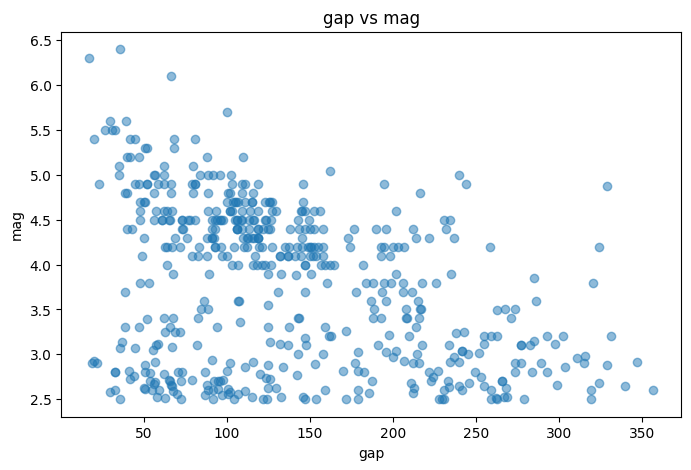

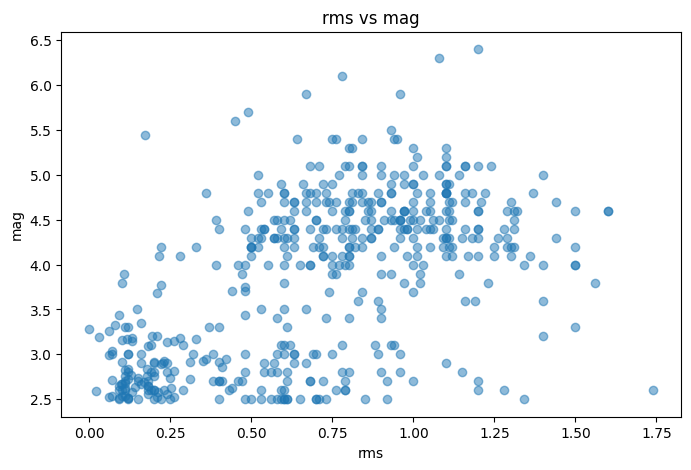

In [36]:
pairs = [
    ('depth', 'mag'),
    ('gap', 'mag'),
    ('rms', 'mag')
]
for x, y in pairs:
    sample_df = dataSet[[x, y]].dropna().sample(500)
    plt.figure(figsize=(8, 5))
    plt.scatter(sample_df[x],
                sample_df[y],
                alpha=0.5)
    plt.title(f'{x} vs {y}')
    plt.xlabel(x)
    plt.ylabel(y)
    plt.show()

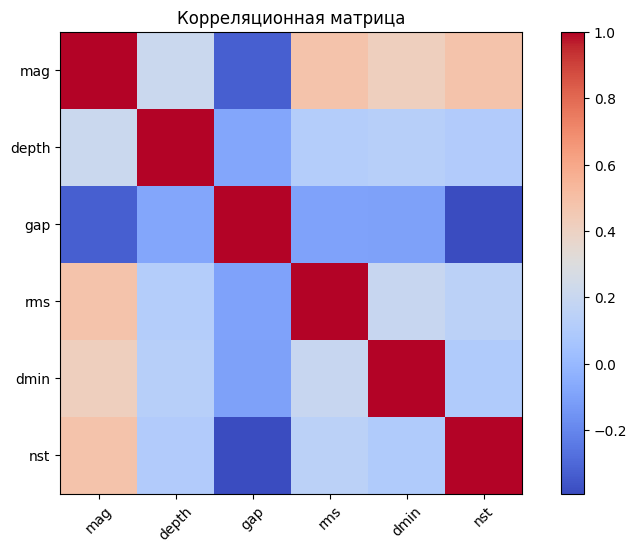

In [37]:

corr_features = ['mag', 'depth', 'gap', 'rms', 'dmin', 'nst']
corr = dataSet[corr_features].corr()
plt.figure(figsize=(10, 6))
plt.imshow(corr,
           cmap='coolwarm')
plt.colorbar()
plt.xticks(range(len(corr.columns)),
           corr.columns,
           rotation=45)
plt.yticks(range(len(corr.columns)),
           corr.columns)
plt.title('Корреляционная матрица')
plt.show()

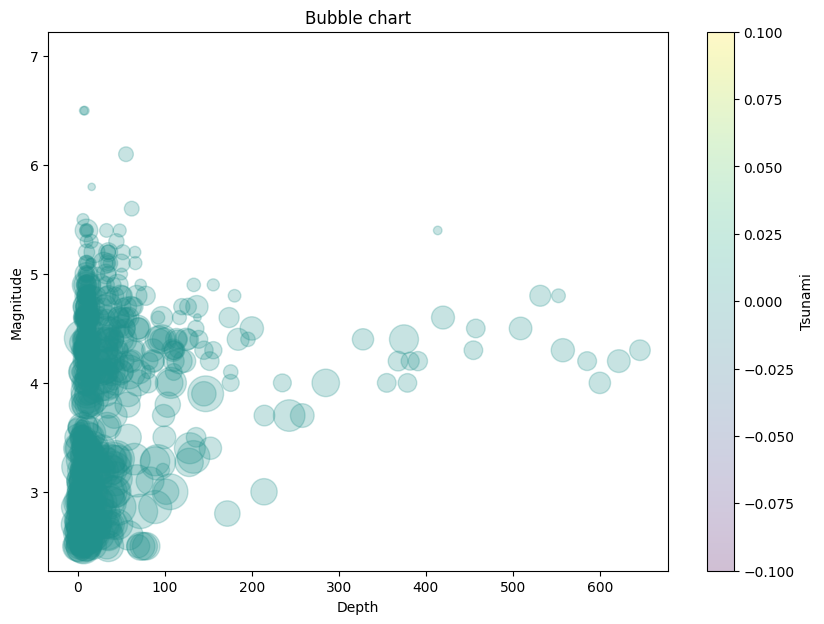

In [38]:
sample_df = dataSet.sample(1000)
sizes = sample_df['gap'].fillna(0) * 2
plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    sample_df['depth'],
    sample_df['mag'],
    s=sizes,
    c=sample_df['tsunami'],
    alpha=0.25
)
plt.title('Bubble chart')
plt.xlabel('Depth')
plt.ylabel('Magnitude')
plt.colorbar(scatter, label='Tsunami')
plt.show()

# Задание 4: Анализ во времени

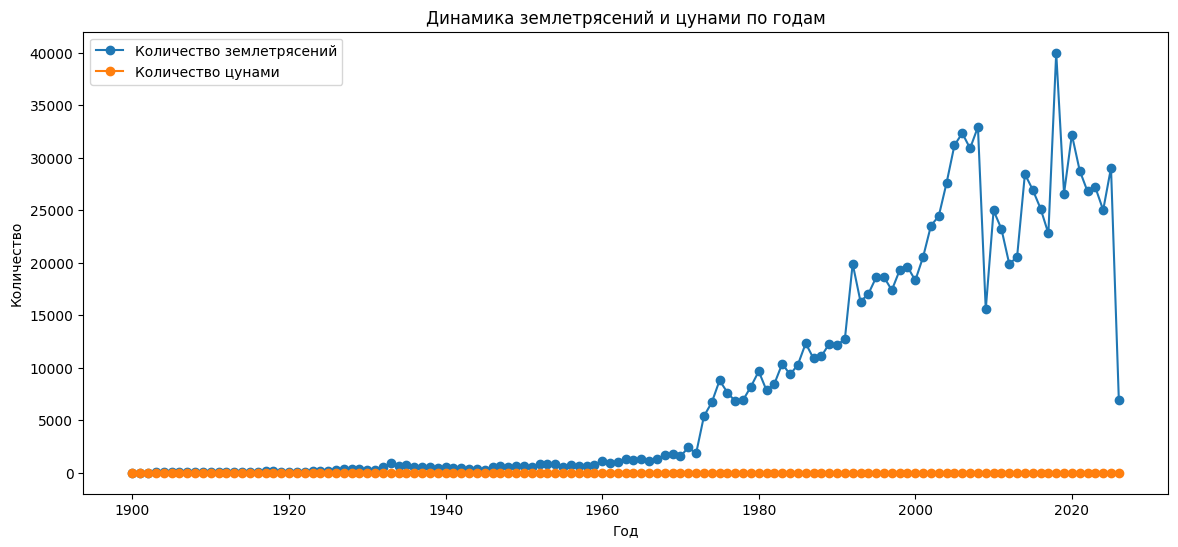

In [39]:
earthquakes_per_year = dataSet.groupby('year').size()
tsunami_per_year = dataSet.groupby('year')['tsunami'].sum()
plt.figure(figsize=(14, 6))
plt.plot(
    earthquakes_per_year.index,
    earthquakes_per_year.values,
    marker='o',
    label='Количество землетрясений'
)
plt.plot(
    tsunami_per_year.index,
    tsunami_per_year.values,
    marker='o',
    label='Количество цунами'
)
plt.title('Динамика землетрясений и цунами по годам')
plt.xlabel('Год')
plt.ylabel('Количество')
plt.legend()
plt.show()

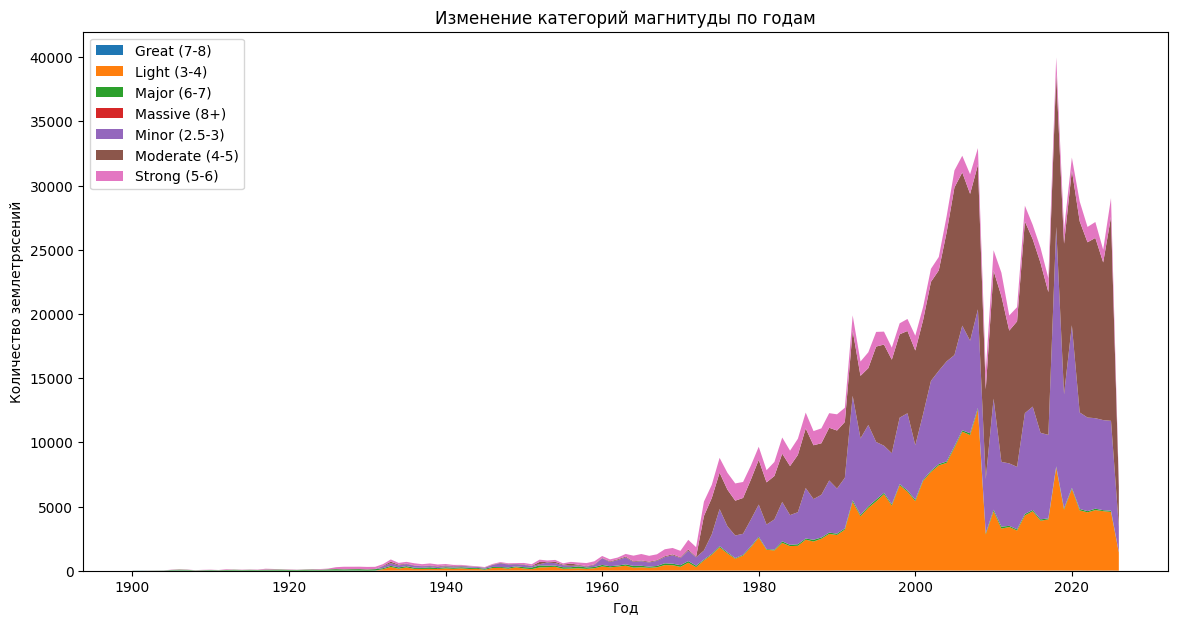

In [40]:
area_data = dataSet.groupby(
    ['year', 'mag_category']
).size().unstack(fill_value=0)
plt.figure(figsize=(14, 7))
plt.stackplot(
    area_data.index,
    area_data.T,
    labels=area_data.columns
)
plt.title('Изменение категорий магнитуды по годам')
plt.xlabel('Год')
plt.ylabel('Количество землетрясений')
plt.legend(loc='upper left')
plt.show()

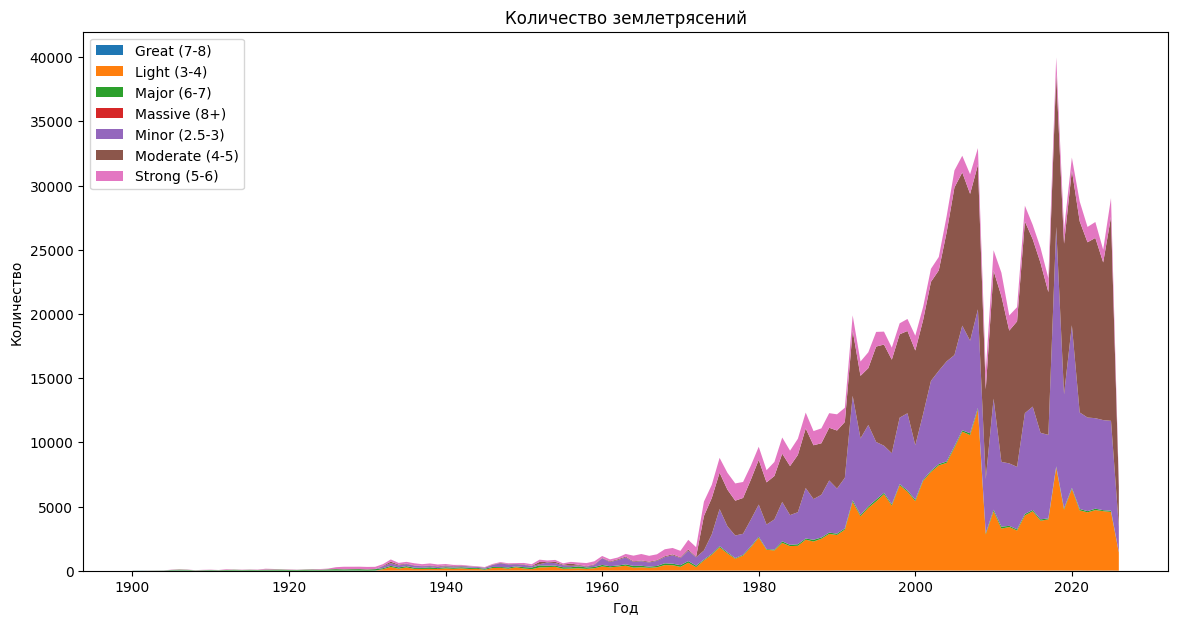

In [41]:
area_data = dataSet.groupby(
    ['year', 'mag_category']
).size().unstack(fill_value=0)
plt.figure(figsize=(14, 7))
plt.stackplot(
    area_data.index,
    area_data.T,
    labels=area_data.columns
)
plt.title('Количество землетрясений')
plt.xlabel('Год')
plt.ylabel('Количество')
plt.legend(loc='upper left')
plt.show()

# Задание 5: Анализ структуры (композиции)

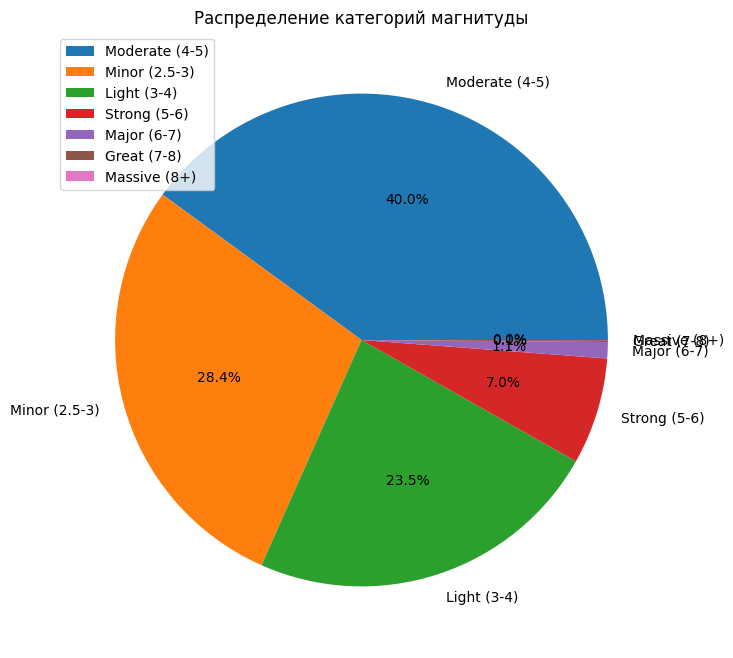

In [42]:
mag_counts = dataSet['mag_category'].value_counts()
plt.figure(figsize=(8, 8))
plt.pie(
    mag_counts.values,
    labels=mag_counts.index,
    autopct='%1.1f%%'
)
plt.legend()
plt.title('Распределение категорий магнитуды')
plt.show()

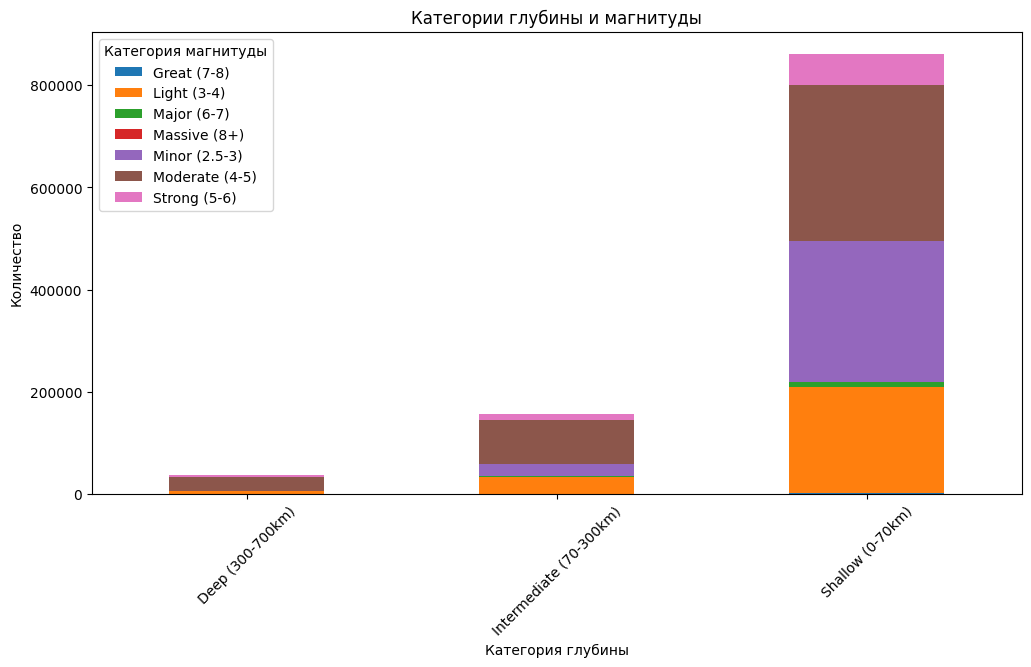

In [43]:
stacked_data = pd.crosstab(
    dataSet['depth_category'],
    dataSet['mag_category']
)
stacked_data.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)
plt.title('Категории глубины и магнитуды')
plt.xlabel('Категория глубины')
plt.ylabel('Количество')
plt.xticks(rotation=45)
plt.legend(title='Категория магнитуды')
plt.show()

# Задание 6: Составная аналитическая визуализация

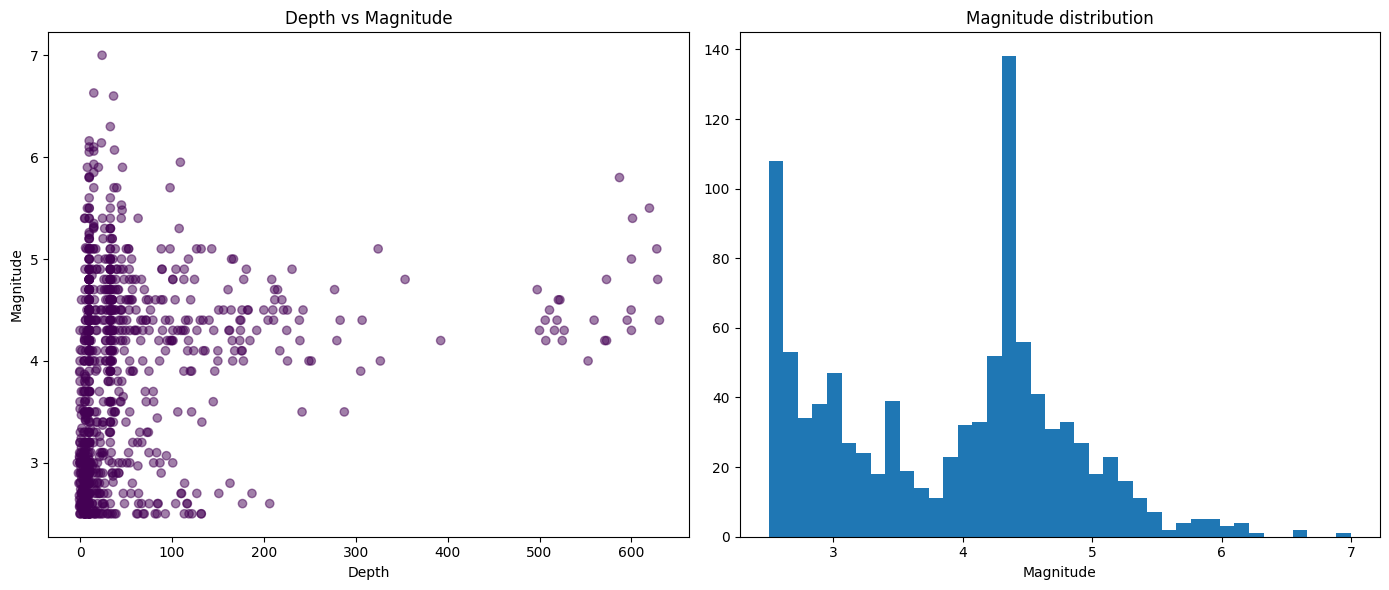

In [44]:
sample_df = dataSet.sample(1000)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
scatter = axes[0].scatter(
    sample_df['depth'],
    sample_df['mag'],
    c=sample_df['tsunami'],
    alpha=0.5
)
axes[0].set_title('Depth vs Magnitude')
axes[0].set_xlabel('Depth')
axes[0].set_ylabel('Magnitude')
axes[1].hist(
    sample_df['mag'],
    bins=40
)
axes[1].set_title('Magnitude distribution')
axes[1].set_xlabel('Magnitude')
plt.tight_layout()
plt.show()

# Задание 7: Data storytelling

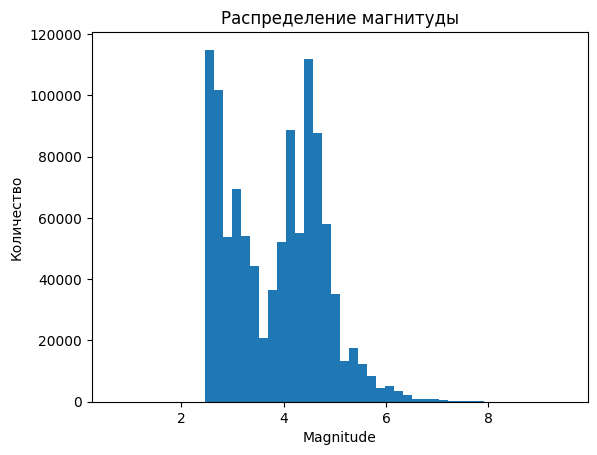

In [45]:
plt.hist(dataSet['mag'],
         bins=50)
plt.title('Распределение магнитуды')
plt.xlabel('Magnitude')
plt.ylabel('Количество')
plt.show()

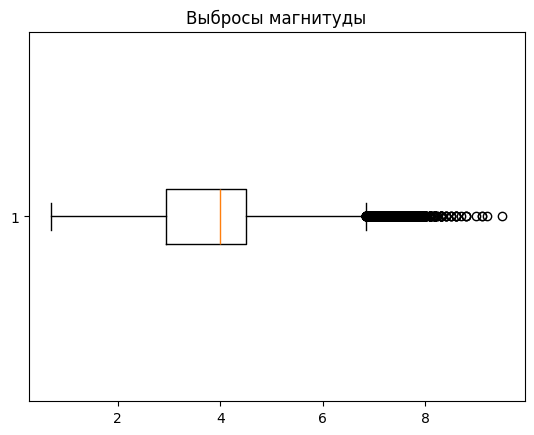

In [46]:
plt.boxplot(dataSet['mag'].dropna(),
            vert=False)
plt.title('Выбросы магнитуды')
plt.show()

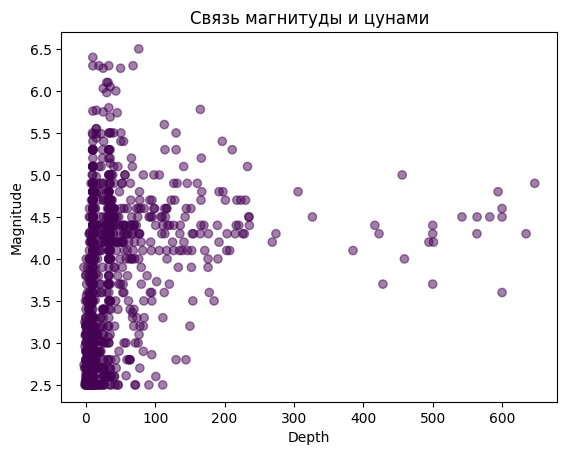

In [47]:
sample_df = dataSet.sample(1000)
plt.scatter(
    sample_df['depth'],
    sample_df['mag'],
    c=sample_df['tsunami'],
    alpha=0.5
)
plt.title('Связь магнитуды и цунами')
plt.xlabel('Depth')
plt.ylabel('Magnitude')
plt.show()

# Задание 8: Мини-дашборд

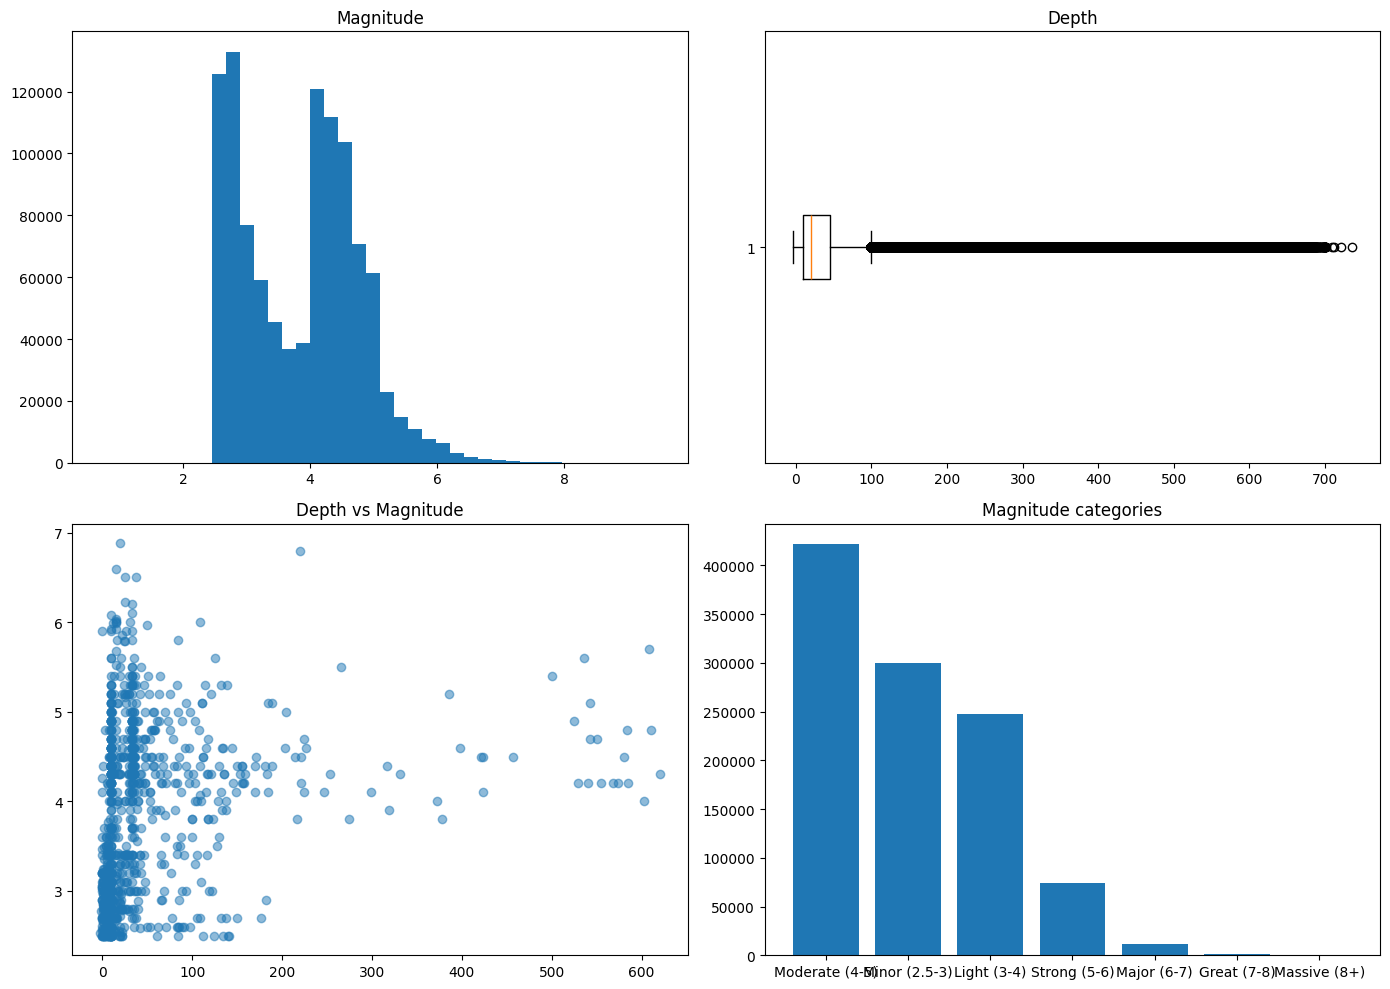

In [48]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].hist(dataSet['mag'],
                bins=40)
axes[0, 0].set_title('Magnitude')
axes[0, 1].boxplot(dataSet['depth'].dropna(),
                   vert=False)
axes[0, 1].set_title('Depth')
sample_df = dataSet.sample(1000)
axes[1, 0].scatter(
    sample_df['depth'],
    sample_df['mag'],
    alpha=0.5
)
axes[1, 0].set_title('Depth vs Magnitude')
counts = dataSet['mag_category'].value_counts()
axes[1, 1].bar(
    counts.index.astype(str),
    counts.values
)
axes[1, 1].set_title('Magnitude categories')
plt.tight_layout()
plt.show()

# Задание 9: Исследовательское задание

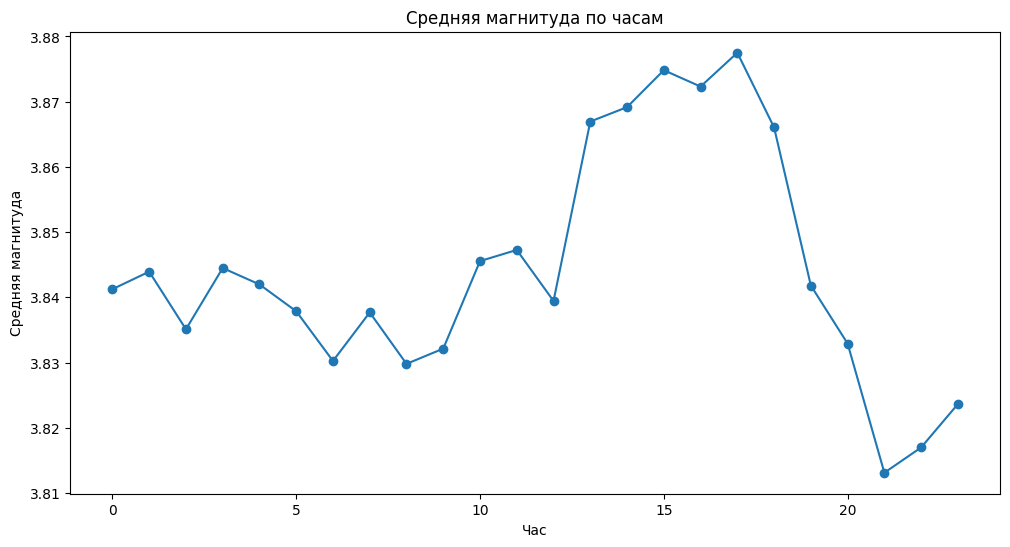

In [49]:
hourly_activity = dataSet.groupby('hour')['mag'].mean()
plt.figure(figsize=(12, 6))
plt.plot(hourly_activity.index,
         hourly_activity.values,
         marker='o')
plt.title('Средняя магнитуда по часам')
plt.xlabel('Час')
plt.ylabel('Средняя магнитуда')
plt.show()